# Four-method DeePC comparison on 1,000 paired Reacher seeds

This notebook compares **Select-DPC**, **Atlas-DeePC**, **Contextual DPC**, and the finalized **Contextual Atlas-DeePC** on seeds 211--1210. Every method uses the same random-walk offline Hankel library, output map, goal-construction rule, rank-60 representation, DeePC cost, constraints, solver, horizon, and environment seed.

The methods differ only in reference policy and in how the behavioral matrix supplied to DeePC is selected or cached. Contextual DPC is included as a neutral comparator; the analysis does not visually emphasize it.

## 1. Comparison contract

| Method | Behavioral matrix supplied to DeePC | Reference policy | Online data work |
|---|---|---|---|
| Select-DPC | Rank-60 SVD of the 200 L1-nearest complete Hankel columns | Atlas graph-routed waypoint | Scores all columns and rebuilds SVD every step |
| Atlas-DeePC | Cached rank-60 basis of the measured physical chart | Atlas graph-routed waypoint | Physical-chart localization and cached lookup |
| Contextual DPC | Rank-60 SVD of the 200 columns nearest in normalized $Y_p$ and $Q$-weighted $Y_f$ | Final graph-compatible goal from step 0 | Scores all columns and rebuilds SVD every step |
| Contextual Atlas-DeePC | Physical chart normally; after a causal stall, one cached rank-60 basis selected from 128 global $[Y_p,Q^{1/2}Y_f]$ prototypes | Atlas graph-routed waypoint and latched terminal goal | Scores 128 prototypes after triggering; no online column search or SVD |

Strict success requires both the final-30 and final-100 mean fingertip errors to be below 1 cm. All reported outcomes are paired by seed.

In [1]:
from pathlib import Path
import json
import math
import os
import subprocess
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    raise RuntimeError('Run this notebook from the atlas_deepc_reacher project root.')

SEEDS = list(range(211, 1211))
SOURCE_COMPARISON = ROOT / 'experiments/deepc_algorithm_comparison/six_way_svd_heldout111_1210_n200_rank60/summary.json'
CONTEXTUAL_ATLAS_FIRST = ROOT / 'experiments/routed_deepc_iid/contextual_cluster_eval211_710_global128_triggered/summary.json'
CONTEXTUAL_ATLAS_EXTENSION = ROOT / 'experiments/routed_deepc_iid/contextual_cluster_eval711_1210_global128_triggered/summary.json'
OUTPUT_DIR = ROOT / 'experiments/deepc_algorithm_comparison/four_method_contextual_atlas_211_1210'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CONTROLLED_TIMING = (
    ROOT / 'experiments/deepc_algorithm_comparison'
    / 'four_method_controlled_serial_211_1210/summary.json'
)

required = [
    SOURCE_COMPARISON, CONTEXTUAL_ATLAS_FIRST, CONTEXTUAL_ATLAS_EXTENSION,
    CONTROLLED_TIMING,
]
assert all(path.exists() for path in required), [path for path in required if not path.exists()]
print(f'Paired evaluation panel: {SEEDS[0]}--{SEEDS[-1]} ({len(SEEDS)} seeds)')

Paired evaluation panel: 211--1210 (1000 seeds)


## 2. Load and audit the paired rollouts

The first three methods are read from the completed 1,100-seed comparison and restricted to the requested 1,000-seed panel. Contextual Atlas-DeePC combines its original seeds 211--710 with the untouched extension 711--1210. No aggregate result is substituted for an individual rollout.

In [2]:
source = json.loads(SOURCE_COMPARISON.read_text())
contextual_first = json.loads(CONTEXTUAL_ATLAS_FIRST.read_text())
contextual_extension = json.loads(CONTEXTUAL_ATLAS_EXTENSION.read_text())

source_keys = {
    'Select-DPC': 'select_dpc_svd',
    'Atlas-DeePC': 'atlas',
    'Contextual DPC': 'contextual_final_svd',
}
results = {}
for label, key in source_keys.items():
    by_seed = {int(row['seed']): row for row in source['method_summaries'][key]}
    results[label] = [by_seed[seed] for seed in SEEDS]

contextual_rows = contextual_first['results'] + contextual_extension['results']
contextual_by_seed = {int(row['seed']): row for row in contextual_rows}
results['Contextual Atlas-DeePC'] = [contextual_by_seed[seed] for seed in SEEDS]

assert all(len(rows) == 1000 for rows in results.values())
assert all([int(row['seed']) for row in rows] == SEEDS for rows in results.values())

reference_config = dict(source['config'])
for payload in [contextual_first, contextual_extension]:
    candidate = dict(payload['config'])
    reference_config.pop('seed', None)
    candidate.pop('seed', None)
    assert candidate == reference_config
    cluster = payload['contextual_cluster']
    assert cluster['architecture'] == 'global_vq'
    assert cluster['contextual_clusters'] == 128
    assert cluster['support_columns'] == 200
    assert cluster['activation_mode'] == 'triggered'

all_rows = [row for rows in results.values() for row in rows]
assert all(row.get('fitted_dynamics_model') is False for row in all_rows)
assert all(row['data_goal_source_target_distance'] >= 0.06 for row in all_rows)
assert all(row['svd_rank'] == 60 for row in all_rows)
assert all(row['steps'] == 320 for row in all_rows)
assert all(row.get('online_svd_rebuild') is False for row in results['Contextual Atlas-DeePC'])
assert all(row.get('online_hankel_columns_scored') == 0 for row in results['Contextual Atlas-DeePC'])

display(pd.Series({
    'paired seed range': f'{SEEDS[0]}--{SEEDS[-1]}',
    'trials per method': len(SEEDS),
    'offline stabilized episodes': contextual_first['fairness_audit']['offline_stabilized_episode_count'],
    'minimum source-target separation': min(row['data_goal_source_target_distance'] for row in all_rows),
    'required source-target separation': 0.06,
    'fitted dynamics / IK feedback / fallback': 'none',
    'Contextual Atlas online full-column scores': 0,
    'Contextual Atlas online SVD rebuilds': 0,
}))

paired seed range                             211--1210
trials per method                                  1000
offline stabilized episodes                           0
minimum source-target separation               0.060243
required source-target separation                  0.06
fitted dynamics / IK feedback / fallback           none
Contextual Atlas online full-column scores            0
Contextual Atlas online SVD rebuilds                  0
dtype: object

## 3. Primary 1,000-seed result

The table uses the same strict sustained criterion for all methods. Confidence intervals are Wilson intervals for the binomial success proportion. Computation comes from a fresh 1,000-seed serial benchmark on this computer: one process, one numerical thread, an excluded warm-up, and method order balanced across seeds. Each value is the median across rollout-level median control-step times after discarding the first five steps.

In [3]:
METHOD_ORDER = ['Select-DPC', 'Atlas-DeePC', 'Contextual DPC', 'Contextual Atlas-DeePC']
controlled_payload = json.loads(CONTROLLED_TIMING.read_text())
controlled_aggregate = {
    row['method']: row for row in controlled_payload['aggregate']
}
controlled_records = pd.DataFrame(controlled_payload['per_seed'])
assert set(controlled_aggregate) == set(METHOD_ORDER)
assert len(controlled_records) == 4 * len(SEEDS)
assert all(controlled_aggregate[method]['rollouts'] == len(SEEDS) for method in METHOD_ORDER)

def strict_success(row):
    return bool(row['success_30'] and row['success_100'])

def wilson(successes, trials, z=1.959963984540054):
    rate = successes / trials
    denominator = 1 + z*z/trials
    center = (rate + z*z/(2*trials)) / denominator
    half = z * np.sqrt(rate*(1-rate)/trials + z*z/(4*trials**2)) / denominator
    return center-half, center+half

def control_timing(row, statistic):
    current = f'{statistic}_control_compute_ms'
    legacy = f'{statistic}_control_compute_time_ms'
    return row[current] if current in row else row[legacy]

summary_rows = []
for method in METHOD_ORDER:
    rows = results[method]
    successes = sum(strict_success(row) for row in rows)
    low, high = wilson(successes, len(rows))
    summary_rows.append({
        'method': method,
        'successes': successes,
        'trials': len(rows),
        'success rate': successes / len(rows),
        'Wilson low': low,
        'Wilson high': high,
        'median final-100 (mm)': 1000*np.median([row['mean_last_100'] for row in rows]),
        'median prediction error (mm)': 1000*np.median([row['mean_prediction_error_xy'] for row in rows]),
        'median online compute (ms)': controlled_aggregate[method]['median total online control (ms)'],
        'p95 rollout-median compute (ms)': np.percentile(
            controlled_records.loc[
                controlled_records['method'] == method, 'total online control'
            ], 95,
        ),
    })

summary = pd.DataFrame(summary_rows).set_index('method')
display(summary.style.format({
    'success rate': '{:.1%}', 'Wilson low': '{:.1%}', 'Wilson high': '{:.1%}',
    'median final-100 (mm)': '{:.3f}', 'median prediction error (mm)': '{:.3f}',
    'median online compute (ms)': '{:.3f}', 'p95 rollout-median compute (ms)': '{:.3f}',
}))

,successes,trials,success rate,Wilson low,Wilson high,median final-100 (mm),median prediction error (mm),median online compute (ms),p95 rollout-median compute (ms)
method,,,,,,,,,
Select-DPC,715,1000,71.5%,68.6%,74.2%,3.593,2.703,59.451,88.736
Atlas-DeePC,883,1000,88.3%,86.2%,90.1%,2.116,1.721,34.776,49.205
Contextual DPC,959,1000,95.9%,94.5%,97.0%,1.703,1.094,58.314,82.255
Contextual Atlas-DeePC,956,1000,95.6%,94.1%,96.7%,2.002,1.707,34.789,50.704


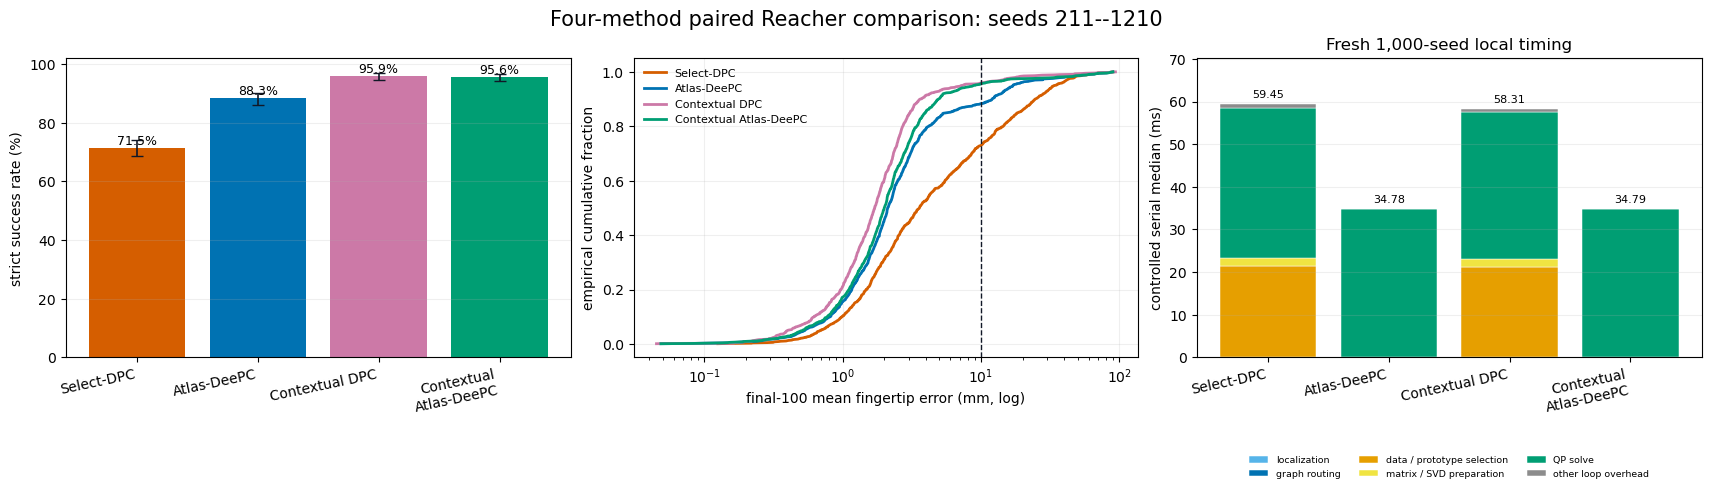

In [4]:
colors = {
    'Select-DPC': '#D55E00',
    'Atlas-DeePC': '#0072B2',
    'Contextual DPC': '#CC79A7',
    'Contextual Atlas-DeePC': '#009E73',
}

def stage_timing(row, stage):
    current = f'median_{stage}_ms'
    legacy = f'median_{stage}_time_ms'
    return float(row.get(current, row.get(legacy, 0.0)))

timing_rows = []
for method in METHOD_ORDER:
    measured = controlled_aggregate[method]
    components = {
        'localization': measured['median localization (ms)'],
        'graph routing': measured['median graph routing (ms)'],
        'data / prototype selection': measured['median data / prototype selection (ms)'],
        'matrix / SVD preparation': measured['median matrix / SVD preparation (ms)'],
        'QP solve': measured['median QP solve (ms)'],
    }
    total = float(summary.loc[method, 'median online compute (ms)'])
    components['other loop overhead'] = max(0.0, total - sum(components.values()))
    timing_rows.append({'method': method, **components, 'total': total})
timing_components = pd.DataFrame(timing_rows).set_index('method')

module_colors = {
    'localization': '#56B4E9',
    'graph routing': '#0072B2',
    'data / prototype selection': '#E69F00',
    'matrix / SVD preparation': '#F0E442',
    'QP solve': '#009E73',
    'other loop overhead': '#8C8C8C',
}
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), constrained_layout=True)

rates = summary.loc[METHOD_ORDER, 'success rate'].to_numpy()
lows = summary.loc[METHOD_ORDER, 'Wilson low'].to_numpy()
highs = summary.loc[METHOD_ORDER, 'Wilson high'].to_numpy()
x = np.arange(len(METHOD_ORDER))
axes[0].bar(x, 100*rates, color=[colors[m] for m in METHOD_ORDER])
axes[0].errorbar(x, 100*rates, yerr=[100*(rates-lows), 100*(highs-rates)],
                 fmt='none', ecolor='#111827', capsize=4, linewidth=1.2)
axes[0].set_ylim(0, 102)
axes[0].set_ylabel('strict success rate (%)')
for index, rate in enumerate(rates):
    axes[0].text(index, 100*rate+1.2, f'{100*rate:.1f}%', ha='center', fontsize=9)

for method in METHOD_ORDER:
    values = np.sort(1000*np.asarray([row['mean_last_100'] for row in results[method]]))
    axes[1].plot(values, np.arange(1, len(values)+1)/len(values),
                 color=colors[method], linewidth=2, label=method)
axes[1].axvline(10, color='#111827', linestyle='--', linewidth=1)
axes[1].set_xscale('log')
axes[1].set_xlabel('final-100 mean fingertip error (mm, log)')
axes[1].set_ylabel('empirical cumulative fraction')
axes[1].legend(frameon=False, fontsize=8)
axes[1].grid(alpha=0.2)

modules = list(module_colors)
bottom = np.zeros(len(METHOD_ORDER))
for module in modules:
    values = timing_components.loc[METHOD_ORDER, module].to_numpy()
    axes[2].bar(x, values, bottom=bottom, color=module_colors[module],
                label=module, edgecolor='white', linewidth=0.35)
    bottom += values
compute = timing_components.loc[METHOD_ORDER, 'total'].to_numpy()
axes[2].set_ylim(0, 1.18 * compute.max())
axes[2].set_ylabel('controlled serial median (ms)')
axes[2].set_title('Fresh 1,000-seed local timing')
for index, value in enumerate(compute):
    axes[2].text(index, value + 0.025*compute.max(), f'{value:.2f}',
                 ha='center', fontsize=8)
axes[2].legend(
    frameon=False, fontsize=6.8, ncol=3, loc='upper center',
    bbox_to_anchor=(0.5, -0.30),
)

short = ['Select-DPC', 'Atlas-DeePC', 'Contextual DPC', 'Contextual\nAtlas-DeePC']
for axis in [axes[0], axes[2]]:
    axis.set_xticks(x, short, rotation=12, ha='right')
    axis.grid(axis='y', alpha=0.2)
fig.suptitle('Four-method paired Reacher comparison: seeds 211--1210', fontsize=15)
plot_path = OUTPUT_DIR / 'four_method_1000_seed_comparison.png'
fig.savefig(plot_path, dpi=170, bbox_inches='tight')
plt.show()

### Controlled serial computation by module

Each entry is the median across 1,000 fresh rollout-level median stage times. Matrix preparation includes the online rank-60 SVD for Select-DPC and Contextual DPC; for both Atlas methods it is a cached-basis lookup. Because medians of separate stages need not add exactly to the median total, **other loop overhead** is the residual required to match the reported median control-compute time.

The benchmark ran in one process with numerical thread counts fixed to one. An untimed warm-up preceded measurement, the first five steps of every rollout were discarded, and each method appeared in each execution position exactly 250 times.

,localization,graph routing,data / prototype selection,matrix / SVD preparation,QP solve,other loop overhead,total
method,,,,,,,
Select-DPC,0.053,0.005,21.406,1.876,35.093,1.019,59.451
Atlas-DeePC,0.060,0.005,0.000,0.001,34.658,0.053,34.776
Contextual DPC,0.000,0.000,21.128,1.944,34.460,0.782,58.314
Contextual Atlas-DeePC,0.060,0.014,0.001,0.001,34.673,0.040,34.789


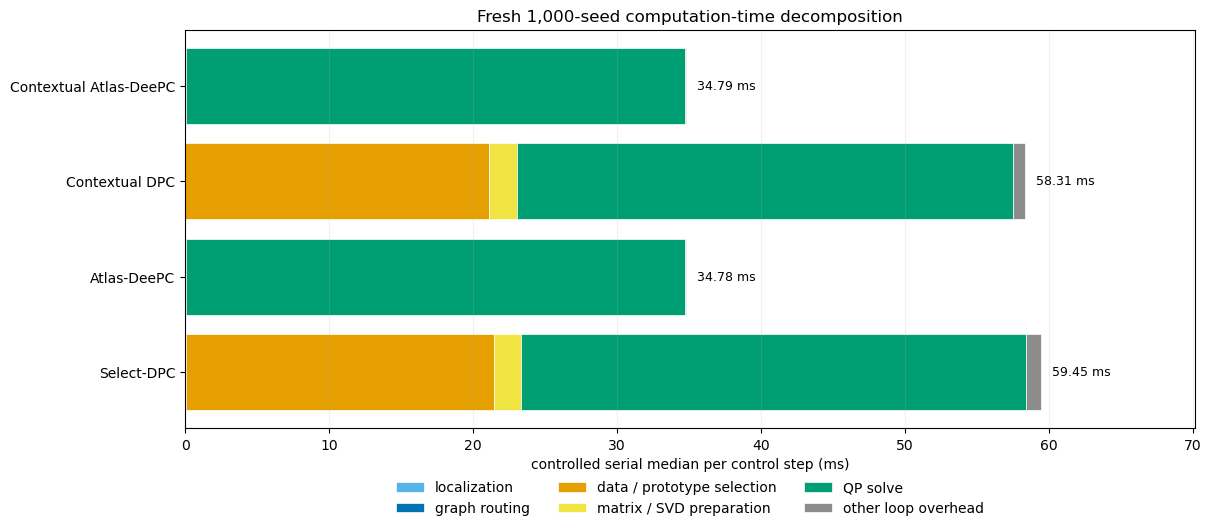

In [5]:
display(timing_components.style.format('{:.3f}'))

fig, ax = plt.subplots(figsize=(12, 5.2), constrained_layout=True)
left = np.zeros(len(METHOD_ORDER))
for module in modules:
    values = timing_components.loc[METHOD_ORDER, module].to_numpy()
    ax.barh(METHOD_ORDER, values, left=left, color=module_colors[module],
            label=module, edgecolor='white', linewidth=0.5)
    left += values
for index, total in enumerate(timing_components.loc[METHOD_ORDER, 'total']):
    ax.text(total + 0.8, index, f'{total:.2f} ms', va='center', fontsize=9)
ax.set_xlim(0, 1.18*timing_components['total'].max())
ax.set_xlabel('controlled serial median per control step (ms)')
ax.set_title('Fresh 1,000-seed computation-time decomposition')
ax.grid(axis='x', alpha=0.2)
ax.legend(frameon=False, ncol=3, loc='lower center', bbox_to_anchor=(0.5, -0.25))
timing_plot_path = OUTPUT_DIR / 'timing_module_breakdown_1000_seeds.png'
fig.savefig(timing_plot_path, dpi=170, bbox_inches='tight')
plt.show()

### Historical parallel-batch timing audit

The earlier multiprocessing batches reported an artificial Contextual Atlas QP gap. An untriggered Contextual Atlas rollout uses the same cached rank-60 physical-chart basis as Atlas-DeePC, and the fresh controlled benchmark above resolves the discrepancy. This audit is retained only to document why parallel-batch wall-clock timing was rejected.

In [6]:
atlas_by_seed = {int(row['seed']): row for row in results['Atlas-DeePC']}
contextual_atlas_by_seed = {
    int(row['seed']): row for row in results['Contextual Atlas-DeePC']
}

def qp_median(row):
    return stage_timing(row, 'solve')

def timing_audit_row(label, seeds):
    atlas_values = np.asarray([qp_median(atlas_by_seed[seed]) for seed in seeds])
    contextual_values = np.asarray([
        qp_median(contextual_atlas_by_seed[seed]) for seed in seeds
    ])
    return {
        'subset': label,
        'seeds': len(seeds),
        'Atlas QP median (ms)': np.median(atlas_values),
        'Contextual Atlas QP median (ms)': np.median(contextual_values),
        'median paired delta (ms)': np.median(contextual_values - atlas_values),
    }

triggered_seeds = [
    seed for seed in SEEDS if contextual_atlas_by_seed[seed]['contextual_triggered']
]
untriggered_seeds = sorted(set(SEEDS) - set(triggered_seeds))
timing_audit = pd.DataFrame([
    timing_audit_row('all seeds', SEEDS),
    timing_audit_row('untriggered', untriggered_seeds),
    timing_audit_row('triggered', triggered_seeds),
    timing_audit_row('first Contextual Atlas batch', list(range(211, 711))),
    timing_audit_row('second Contextual Atlas batch', list(range(711, 1211))),
]).set_index('subset')
display(timing_audit.style.format({
    'Atlas QP median (ms)': '{:.3f}',
    'Contextual Atlas QP median (ms)': '{:.3f}',
    'median paired delta (ms)': '{:+.3f}',
}))

display(Markdown(f'''The untriggered subset still shows a reported QP gap, while the two
Contextual Atlas batches show materially different QP medians under the same algorithm and
rank. This identifies batch load, process contention, scheduling, and machine state as the
dominant explanation. Triggered contextual bases may change numerical conditioning on the
{len(triggered_seeds)} triggered seeds, but they cannot explain the untriggered gap.'''))

,seeds,Atlas QP median (ms),Contextual Atlas QP median (ms),median paired delta (ms)
subset,,,,
all seeds,1000,40.847,56.456,+13.915
untriggered,875,40.536,56.229,+13.837
triggered,125,41.660,59.008,+15.613
first Contextual Atlas batch,500,45.144,51.823,+6.540
second Contextual Atlas batch,500,39.466,61.586,+22.225


The untriggered subset still shows a reported QP gap, while the two
Contextual Atlas batches show materially different QP medians under the same algorithm and
rank. This identifies batch load, process contention, scheduling, and machine state as the
dominant explanation. Triggered contextual bases may change numerical conditioning on the
125 triggered seeds, but they cannot explain the untriggered gap.

## 4. Paired statistical comparisons

McNemar's exact test uses only seeds on which a pair of methods disagree. The table reports how many successes are unique to Contextual Atlas-DeePC, how many successes are unique to the comparator, and the two-sided exact $p$-value. This is a paired diagnostic, not an independence test across methods.

In [7]:
def exact_mcnemar_p(first_only, second_only):
    discordant = first_only + second_only
    if discordant == 0:
        return 1.0
    smaller = min(first_only, second_only)
    tail = sum(math.comb(discordant, k) for k in range(smaller + 1))
    return min(1.0, 2.0 * tail / (2 ** discordant))

context_success = np.asarray([strict_success(row) for row in results['Contextual Atlas-DeePC']])
paired_rows = []
for comparator in METHOD_ORDER[:-1]:
    other = np.asarray([strict_success(row) for row in results[comparator]])
    contextual_only = int(np.sum(context_success & ~other))
    comparator_only = int(np.sum(~context_success & other))
    paired_rows.append({
        'comparator': comparator,
        'Contextual Atlas only': contextual_only,
        'comparator only': comparator_only,
        'net successes': contextual_only - comparator_only,
        'exact McNemar p': exact_mcnemar_p(contextual_only, comparator_only),
    })
display(pd.DataFrame(paired_rows).set_index('comparator').style.format({'exact McNemar p': '{:.4g}'}))

,Contextual Atlas only,comparator only,net successes,exact McNemar p
comparator,,,,
Select-DPC,258,17,241,1.76e-56
Atlas-DeePC,80,7,73,8.256e-17
Contextual DPC,24,27,-3,0.7798


## 5. Failure structure and contextual activation

The activation plot is specific to Contextual Atlas-DeePC. A zero fraction means the rollout completed entirely with the physical Atlas; a positive fraction is the portion of control steps after the terminal-stall trigger.

,failures,ever within 1 cm,ever within 2 cm,never within 2 cm
method,,,,
Select-DPC,285,173,243,42
Atlas-DeePC,117,34,88,29
Contextual DPC,41,26,32,9
Contextual Atlas-DeePC,44,19,24,20


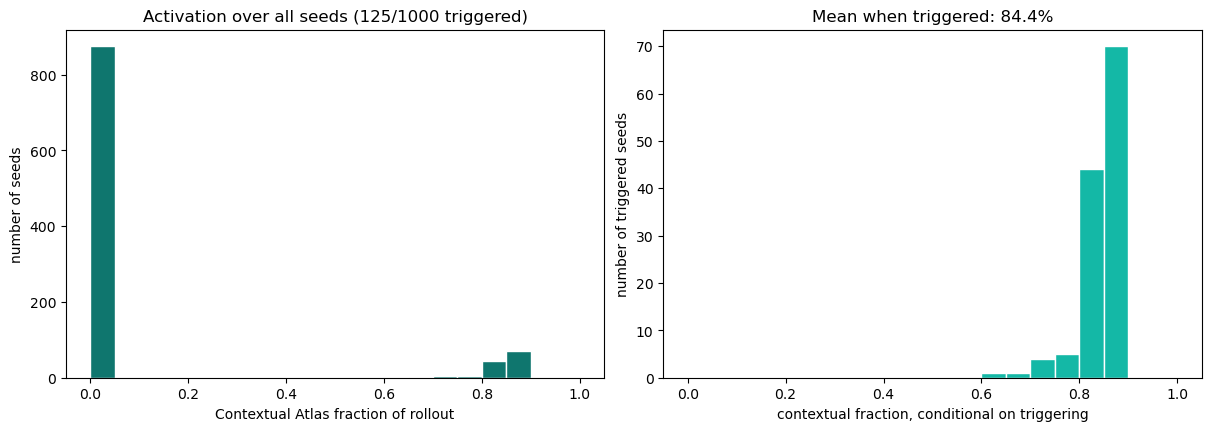

In [8]:
context_rows = results['Contextual Atlas-DeePC']
triggered = [row for row in context_rows if row['contextual_triggered']]
fractions = np.asarray([row['contextual_usage_fraction'] for row in context_rows])

failure_table = []
for method in METHOD_ORDER:
    failed = [row for row in results[method] if not strict_success(row)]
    failure_table.append({
        'method': method,
        'failures': len(failed),
        'ever within 1 cm': sum(row['minimum'] < 0.01 for row in failed),
        'ever within 2 cm': sum(row['minimum'] < 0.02 for row in failed),
        'never within 2 cm': sum(row['minimum'] >= 0.02 for row in failed),
    })
display(pd.DataFrame(failure_table).set_index('method'))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)
axes[0].hist(fractions, bins=np.linspace(0, 1, 21), color='#0F766E', edgecolor='white')
axes[0].set_xlabel('Contextual Atlas fraction of rollout')
axes[0].set_ylabel('number of seeds')
axes[0].set_title(f'Activation over all seeds ({len(triggered)}/1000 triggered)')

triggered_fractions = fractions[fractions > 0]
axes[1].hist(triggered_fractions, bins=np.linspace(0, 1, 21), color='#14B8A6', edgecolor='white')
axes[1].set_xlabel('contextual fraction, conditional on triggering')
axes[1].set_ylabel('number of triggered seeds')
axes[1].set_title(f'Mean when triggered: {triggered_fractions.mean():.1%}')
activation_path = OUTPUT_DIR / 'contextual_atlas_activation_1000_seeds.png'
fig.savefig(activation_path, dpi=170, bbox_inches='tight')
plt.show()

## 6. Interpretation

This section is generated from the paired outcomes rather than from rounded aggregate rates.

In [9]:
contextual_dpc_success = int(summary.loc['Contextual DPC', 'successes'])
contextual_atlas_success = int(summary.loc['Contextual Atlas-DeePC', 'successes'])
comparison_row = next(row for row in paired_rows if row['comparator'] == 'Contextual DPC')
atlas_time = summary.loc['Atlas-DeePC', 'median online compute (ms)']
select_time = summary.loc['Select-DPC', 'median online compute (ms)']
contextual_dpc_time = summary.loc['Contextual DPC', 'median online compute (ms)']
contextual_atlas_time = summary.loc['Contextual Atlas-DeePC', 'median online compute (ms)']
display(Markdown(f'''
Contextual Atlas-DeePC succeeds on **{contextual_atlas_success}/1000** seeds, compared with
**{contextual_dpc_success}/1000** for final-reference Contextual DPC. Their net difference is
{contextual_atlas_success-contextual_dpc_success:+d} seeds, with paired exact McNemar
$p={comparison_row['exact McNemar p']:.3f}$; this panel does not establish a success-rate
difference between them.

Contextual Atlas-DeePC scores no full Hankel columns and rebuilds no SVD online. It triggers on
**{len(triggered)}/1000** rollouts; the remaining {1000-len(triggered)} rollouts use only the
physical Atlas basis. In the fresh controlled benchmark it requires **{contextual_atlas_time:.2f}
ms** per control step, statistically indistinguishable at this resolution from physical
Atlas-DeePC's **{atlas_time:.2f} ms**. Cached Atlas control is **{1-atlas_time/select_time:.1%}
faster** than Select-DPC, while Contextual Atlas is **{1-contextual_atlas_time/contextual_dpc_time:.1%}
faster** than full online Contextual DPC.
'''))


Contextual Atlas-DeePC succeeds on **956/1000** seeds, compared with
**959/1000** for final-reference Contextual DPC. Their net difference is
-3 seeds, with paired exact McNemar
$p=0.780$; this panel does not establish a success-rate
difference between them.

Contextual Atlas-DeePC scores no full Hankel columns and rebuilds no SVD online. It triggers on
**125/1000** rollouts; the remaining 875 rollouts use only the
physical Atlas basis. In the fresh controlled benchmark it requires **34.79
ms** per control step, statistically indistinguishable at this resolution from physical
Atlas-DeePC's **34.78 ms**. Cached Atlas control is **41.5%
faster** than Select-DPC, while Contextual Atlas is **40.3%
faster** than full online Contextual DPC.


## 7. Save the compact comparison record

The full rollout files remain in their original experiment directories. This notebook writes only a compact per-seed comparison record and the aggregate table, avoiding another copy of the numerical trajectories.

In [10]:
compact = {
    'seed_range': [SEEDS[0], SEEDS[-1]],
    'trials_per_method': len(SEEDS),
    'strict_success_definition': 'mean_last_30 < 0.01 m and mean_last_100 < 0.01 m',
    'methods': summary.reset_index().to_dict(orient='records'),
    'per_seed': {
        method: [{
            'seed': int(row['seed']),
            'success': strict_success(row),
            'mean_last_30': float(row['mean_last_30']),
            'mean_last_100': float(row['mean_last_100']),
            'minimum': float(row['minimum']),
            'median_control_compute_ms': float(
                controlled_records.loc[
                    (controlled_records['method'] == method)
                    & (controlled_records['seed'] == int(row['seed'])),
                    'total online control',
                ].iloc[0]
            ),
        } for row in results[method]]
        for method in METHOD_ORDER
    },
    'sources': {
        'three_comparators': str(SOURCE_COMPARISON),
        'contextual_atlas_211_710': str(CONTEXTUAL_ATLAS_FIRST),
        'contextual_atlas_711_1210': str(CONTEXTUAL_ATLAS_EXTENSION),
    },
}
compact_path = OUTPUT_DIR / 'summary.json'
compact_path.write_text(json.dumps(compact, indent=2))
print('Saved:', compact_path)

Saved: /Users/kumiko/Projects/atlas_deepc_reacher/experiments/deepc_algorithm_comparison/four_method_contextual_atlas_211_1210/summary.json


## 8. Controlled runtime on this computer

The outcome experiment above remains the saved 1,000-seed paired panel. The cell below is a separate **fresh serial timing benchmark** for measuring computation on the computer executing this notebook. It runs the exact four controller paths in one process, forces numerical libraries to one thread, performs an untimed warm-up, rotates method order across seeds, and never resumes or bootstraps old rollout timings.

Set only `RUN_CONTROLLED_TIMING=True` to execute it. The default range is the full 1,000 seeds, which can take many hours because all four 320-step rollouts are executed serially. A range such as 211--310 is sufficient for a shorter 100-seed latency study; success-rate claims should continue to use the original 1,000-seed outcome panel.

Controlled timing is disabled. Set RUN_CONTROLLED_TIMING=True to run it.


,rollouts,median localization (ms),median graph routing (ms),median data / prototype selection (ms),median matrix / SVD preparation (ms),median QP solve (ms),median total online control (ms)
method,,,,,,,
Select-DPC,1000,0.053,0.005,21.406,1.876,35.093,59.451
Atlas-DeePC,1000,0.060,0.005,0.000,0.001,34.658,34.776
Contextual DPC,1000,0.000,0.000,21.128,1.944,34.460,58.314
Contextual Atlas-DeePC,1000,0.060,0.014,0.001,0.001,34.673,34.789


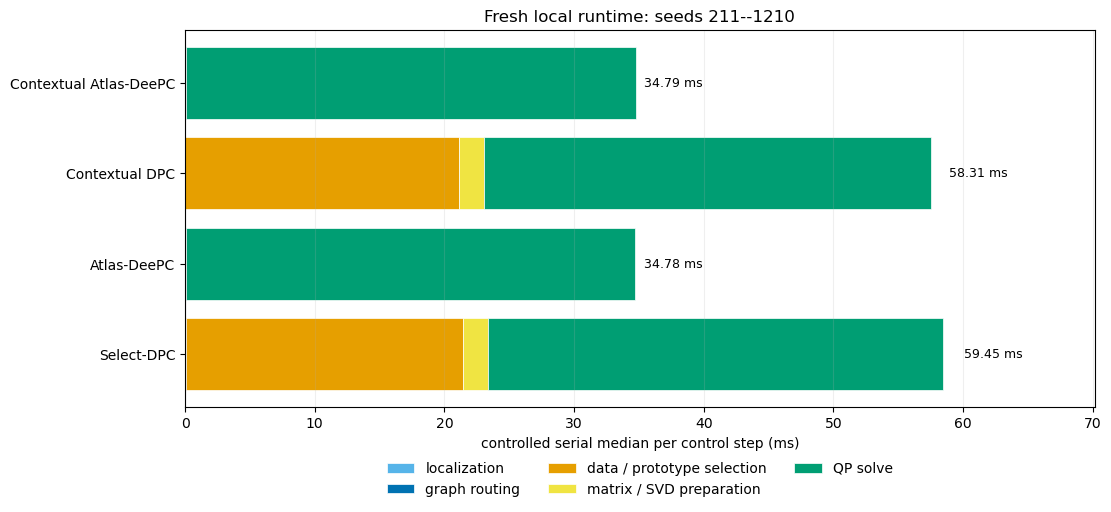

In [11]:
RUN_CONTROLLED_TIMING = False
TIMING_SEED_START = 211
TIMING_SEED_STOP = 1210
TIMING_OUTPUT_DIR = (
    ROOT / 'experiments/deepc_algorithm_comparison'
    / f'four_method_controlled_serial_{TIMING_SEED_START}_{TIMING_SEED_STOP}'
)

run_env = os.environ.copy()
run_env.setdefault('MPLCONFIGDIR', '/tmp/atlas_deepc_mpl')
timing_command = [
    sys.executable, 'src/four_method_serial_timing.py',
    '--seed-start', str(TIMING_SEED_START),
    '--seed-stop', str(TIMING_SEED_STOP),
    '--steps', '320',
    '--warmup-seed', '210',
    '--warmup-steps', '10',
    '--discard-initial-steps', '5',
    '--output-dir', str(TIMING_OUTPUT_DIR),
]

if RUN_CONTROLLED_TIMING:
    subprocess.run(timing_command, cwd=ROOT, env=run_env, check=True)
else:
    print('Controlled timing is disabled. Set RUN_CONTROLLED_TIMING=True to run it.')

timing_summary_path = TIMING_OUTPUT_DIR / 'summary.json'
if timing_summary_path.exists():
    controlled = json.loads(timing_summary_path.read_text())
    controlled_table = pd.DataFrame(controlled['aggregate']).set_index('method')
    display(controlled_table.style.format('{:.3f}', subset=controlled_table.columns[1:]))

    controlled_modules = [
        'median localization (ms)',
        'median graph routing (ms)',
        'median data / prototype selection (ms)',
        'median matrix / SVD preparation (ms)',
        'median QP solve (ms)',
    ]
    fig, ax = plt.subplots(figsize=(11, 5), constrained_layout=True)
    left = np.zeros(len(METHOD_ORDER))
    for module, color in zip(controlled_modules, module_colors.values()):
        values = controlled_table.loc[METHOD_ORDER, module].to_numpy()
        label = module.removeprefix('median ').removesuffix(' (ms)')
        ax.barh(METHOD_ORDER, values, left=left, color=color, label=label,
                edgecolor='white', linewidth=0.5)
        left += values
    totals = controlled_table.loc[METHOD_ORDER, 'median total online control (ms)']
    for index, value in enumerate(totals):
        ax.text(value + 0.6, index, f'{value:.2f} ms', va='center', fontsize=9)
    ax.set_xlim(0, 1.18 * totals.max())
    ax.set_xlabel('controlled serial median per control step (ms)')
    ax.set_title(
        f'Fresh local runtime: seeds {TIMING_SEED_START}--{TIMING_SEED_STOP}'
    )
    ax.grid(axis='x', alpha=0.2)
    ax.legend(frameon=False, ncol=3, loc='lower center', bbox_to_anchor=(0.5, -0.27))
    plt.show()
else:
    print('No controlled local timing summary exists yet:', timing_summary_path)